In [1]:
# 1) Kurulum ve veri setini indirme
!pip install -q ultralytics roboflow
from kaggle_secrets import UserSecretsClient
from roboflow import Roboflow
api_key = UserSecretsClient().get_secret("api_key")
rf = Roboflow(api_key=api_key)
project = rf.workspace("visionspace-adnsg").project("ai-smart-restaurant-surveillance-veh3i")
dataset = project.version(10).download("yolov8")
print("Veri seti konumu:", dataset.location)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 22.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 17.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 80.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 4.1 MB/s eta 0:00:00
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to AI-Smart-Restaurant-Surveillance-10 in yolov8:: 100%|██████████| 10500/10500 [00:01<00:00, 8783.43it/s]


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Veri seti konumu: /kaggle/working/AI-Smart-Restaurant-Surveillance-10


VERİ SETİ GENEL BAKIŞ (GÖRÜNTÜ VE NESNE İSTATİSTİKLERİ)


,Görüntü Sayısı,Toplam Nesne (BBox),Ort. Nesne / Görüntü,Görüntü Oranı (%)
test,780,34159,43.79,%14.87
train,3366,152736,45.38,%64.19
valid,1098,48304,43.99,%20.94



SINIF BAZINDA ETİKET DAĞILIM TABLOSU:


split,train,valid,test,Toplam,Dağılım (%)
sinif,,,,,
cleaning_item,246,71,56,373,%0.16
buffet_zone,579,185,128,892,%0.38
finished_food,1059,305,231,1595,%0.68
takeaway_bag,1341,374,265,1980,%0.84
staff,2925,911,606,4442,%1.89
counter,3360,1094,775,5229,%2.22
kitchen,3366,1098,779,5243,%2.23
menu_card,4731,1462,1052,7245,%3.08
waiter,5235,1728,1170,8133,%3.46


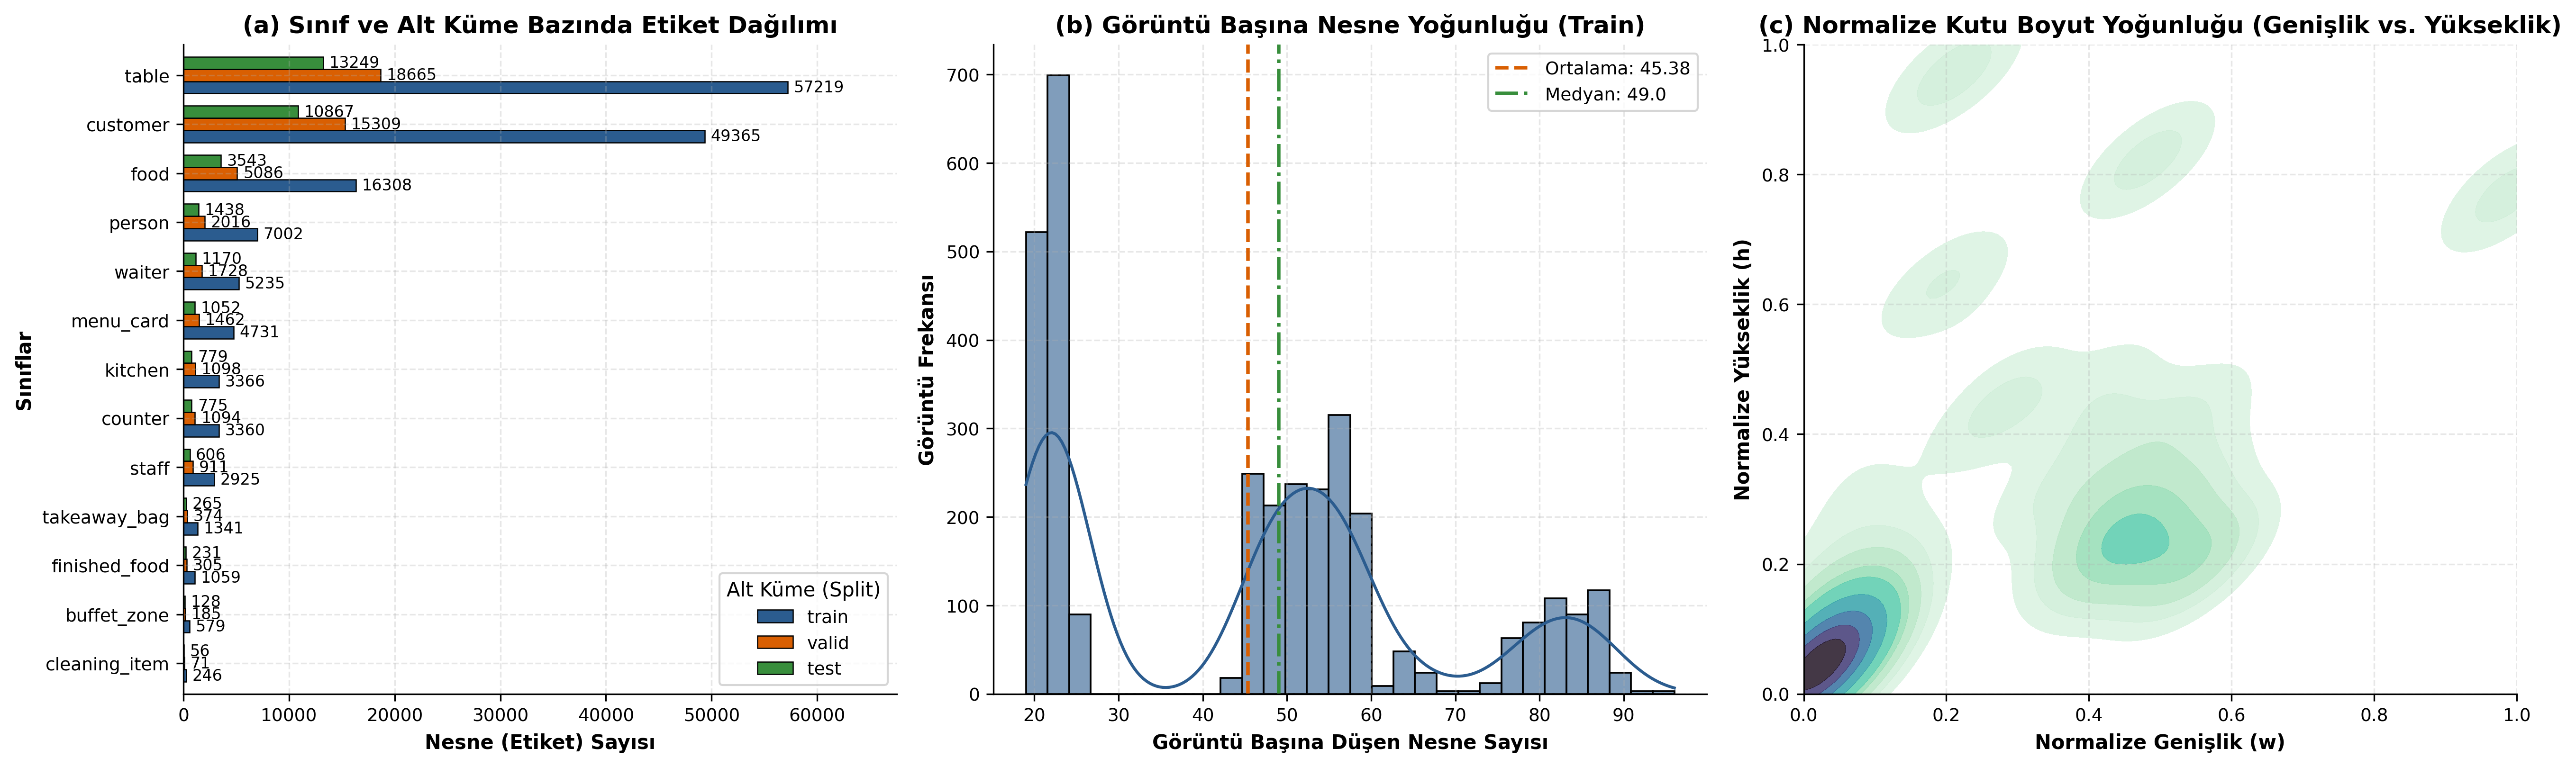

In [2]:
# 2) Akademik Düzeyde Keşifsel Veri Analizi (EDA)
from pathlib import Path
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# --- 1. GÖRSEL VE AKADEMİK STİL AYARLARI ---
plt.rcParams.update({
    "figure.dpi": 300,
    "savefig.dpi": 300,
    "font.family": "sans-serif",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "axes.labelweight": "bold",
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "grid.linestyle": "--"
})
PALETTE = ["#2b5c8f", "#d95f02", "#388e3c"]  # Akademik renk körlüğü dostu palet

# --- 2. VERİ SETİ OKUMA VE GENİŞLETİLEBİLİR AYRIŞTIRMA ---
root = Path(dataset.location)
with open(root / "data.yaml", "r", encoding="utf-8") as f:
    data_cfg = yaml.safe_load(f)

raw_names = data_cfg["names"]
names = list(raw_names.values()) if isinstance(raw_names, dict) else raw_names
splits = ["train", "valid", "test"]

img_counts = {}
bbox_records = []
objects_per_image = {s: [] for s in splits}

for s in splits:
    img_dir = root / s / "images"
    lbl_dir = root / s / "labels"
    
    imgs = list(img_dir.glob("*.*")) if img_dir.exists() else []
    lbls = list(lbl_dir.glob("*.txt")) if lbl_dir.exists() else []
    img_counts[s] = len(imgs)
    
    for lbl_path in lbls:
        with open(lbl_path, "r", encoding="utf-8") as lf:
            lines = [line.strip() for line in lf.read().splitlines() if line.strip()]
            
        objects_per_image[s].append(len(lines))
        
        for line in lines:
            parts = line.split()
            cls_id = int(parts[0])
            # Genişletilebilir yapı: Koordinat ve boyut bilgilerini de kaydediyoruz
            x_c, y_c, w, h = map(float, parts[1:5])
            bbox_records.append({
                "split": s,
                "sinif_id": cls_id,
                "sinif": names[cls_id],
                "x_center": x_c,
                "y_center": y_c,
                "width": w,
                "height": h,
                "area": w * h,
                "aspect_ratio": w / (h + 1e-6)
            })

df_bboxes = pd.DataFrame(bbox_records)

# --- 3. AKADEMİK ÖZET TABLOLARI ---
print("=" * 65)
print("VERİ SETİ GENEL BAKIŞ (GÖRÜNTÜ VE NESNE İSTATİSTİKLERİ)")
print("=" * 65)
ozet_df = pd.DataFrame({
    "Görüntü Sayısı": pd.Series(img_counts),
    "Toplam Nesne (BBox)": df_bboxes.groupby("split").size(),
    "Ort. Nesne / Görüntü": {s: np.mean(objects_per_image[s]) if objects_per_image[s] else 0 for s in splits}
}).fillna(0)
ozet_df["Görüntü Oranı (%)"] = (ozet_df["Görüntü Sayısı"] / ozet_df["Görüntü Sayısı"].sum() * 100).round(2)
display(ozet_df.style.format({
    "Görüntü Sayısı": "{:.0f}",
    "Toplam Nesne (BBox)": "{:.0f}",
    "Ort. Nesne / Görüntü": "{:.2f}",
    "Görüntü Oranı (%)": "%{:.2f}"
}).background_gradient(cmap="Blues", subset=["Görüntü Sayısı", "Toplam Nesne (BBox)"]))

# Sınıf x Split Çapraz Tablosu
tablo = df_bboxes.groupby(["sinif", "split"]).size().unstack(fill_value=0)
# Sütun sırasını standartlaştır
tablo = tablo.reindex(columns=[s for s in splits if s in tablo.columns], fill_value=0)
tablo["Toplam"] = tablo.sum(axis=1)
tablo["Dağılım (%)"] = (tablo["Toplam"] / tablo["Toplam"].sum() * 100).round(2)
tablo = tablo.sort_values(by="Toplam", ascending=True)

print("\nSINIF BAZINDA ETİKET DAĞILIM TABLOSU:")
display(tablo.style.format({"Dağılım (%)": "%{:.2f}"}).background_gradient(cmap="YlGnBu", subset=["Toplam"]))

# --- 4. YAYIN KALİTESİNDE GÖRSELLEŞTİRME (3 PANELLİ FİGÜR) ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# Panel (a): Sınıf Başına Etiket Sayısı (Gruplandırılmış Yatay Bar)
split_cols = [s for s in splits if s in tablo.columns]
tablo[split_cols].plot(
    kind="barh",
    ax=axes[0],
    color=PALETTE[:len(split_cols)],
    edgecolor="black",
    linewidth=0.6,
    width=0.75
)
axes[0].set_title("(a) Sınıf ve Alt Küme Bazında Etiket Dağılımı")
axes[0].set_xlabel("Nesne (Etiket) Sayısı")
axes[0].set_ylabel("Sınıflar")
axes[0].legend(title="Alt Küme (Split)", frameon=True, facecolor="white")

# Barların ucuna toplam sayı yazdırma
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%d", padding=3, fontsize=8)
axes[0].set_xlim(0, tablo[split_cols].values.max() * 1.18)

# Panel (b): Görüntü Başına Nesne Sayısı Dağılımı (Train Kümesi)
train_obj = pd.Series(objects_per_image["train"])
mean_val, median_val = train_obj.mean(), train_obj.median()

sns.histplot(
    train_obj, bins=min(30, int(train_obj.max()) + 1), kde=True,
    ax=axes[1], color="#2b5c8f", edgecolor="black", alpha=0.6
)
axes[1].axvline(mean_val, color="#d95f02", linestyle="--", linewidth=1.8, label=f"Ortalama: {mean_val:.2f}")
axes[1].axvline(median_val, color="#388e3c", linestyle="-.", linewidth=1.8, label=f"Medyan: {median_val:.1f}")
axes[1].set_title("(b) Görüntü Başına Nesne Yoğunluğu (Train)")
axes[1].set_xlabel("Görüntü Başına Düşen Nesne Sayısı")
axes[1].set_ylabel("Görüntü Frekansı")
axes[1].legend(frameon=True, facecolor="white")

# Panel (c): Sınırlayıcı Kutu (BBox) Boyut Analizi (Genişletilmiş Özellik)
sns.kdeplot(
    data=df_bboxes.sample(min(len(df_bboxes), 5000), random_state=42),
    x="width", y="height", fill=True, cmap="mako_r", thresh=0.05, alpha=0.85, ax=axes[2]
)
axes[2].set_title("(c) Normalize Kutu Boyut Yoğunluğu (Genişlik vs. Yükseklik)")
axes[2].set_xlabel("Normalize Genişlik (w)")
axes[2].set_ylabel("Normalize Yükseklik (h)")
axes[2].set_xlim(0, 1)
axes[2].set_ylim(0, 1)

plt.tight_layout()
# Makale veya rapor için kaydetmek istersen alt satırın yorumunu kaldırabilirsin:
# plt.savefig("eda_analiz_raporu.pdf", bbox_inches="tight")
plt.show()

In [3]:
import glob, os
for f in glob.glob(f"{dataset.location}/*/labels/*.txt"):
    out = []
    for l in open(f).read().splitlines():
        p = l.split()
        if len(p) > 5:
            xs, ys = list(map(float, p[1::2])), list(map(float, p[2::2]))
            x1, x2, y1, y2 = min(xs), max(xs), min(ys), max(ys)
            l = f"{p[0]} {(x1+x2)/2:.6f} {(y1+y2)/2:.6f} {x2-x1:.6f} {y2-y1:.6f}"
        if l.strip():
            out.append(l)
    open(f, "w").write("\n".join(out) + "\n")
for c in glob.glob(f"{dataset.location}/*/labels.cache"):
    os.remove(c)
print("Etiketler kutuya cevrildi")

Etiketler kutuya cevrildi


In [4]:
# 3) Egitim
from ultralytics import YOLO
model = YOLO("yolo11n.pt")
model.train(data=f"{dataset.location}/data.yaml", epochs=50, imgsz=640, device=0)

Ultralytics 8.4.180 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/AI-Smart-Restaurant-Surveillance-10/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, op

`get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.


       2/50      3.81G        1.1     0.6716     0.9072        524        640: 100% ━━━━━━━━━━━━ 211/211 7.6it/s 27.9s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 35/35 6.1it/s 5.8s
                   all       1098      48304      0.685      0.546      0.546      0.361

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/50      3.81G       1.03     0.6005     0.8877        340        640: 100% ━━━━━━━━━━━━ 211/211 7.4it/s 28.7s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 35/35 6.0it/s 5.8s
                   all       1098      48304      0.767      0.553      0.575      0.385

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/50      3.81G     0.9959     0.5667     0.8764        415        640: 100% ━━━━━━━━━━━━ 211/211 7.4it/s 28.6s
                 Class     Images  Instances      Box

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x79787ff0d6a0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.04504